# Práctica 4 · Alternativa RT-DETR: detección, seguimiento y conteo

---

Este cuaderno resuelve la práctica con detectores **RT-DETR** y compara el resultado con la alternativa YOLO. Procesa el vídeo `video_practica.MP4` y:

1. **Detecta y sigue personas y vehículos** con RT-DETRv2-L preentrenado en COCO y un seguidor programado por nosotros al estilo ByteTrack.
2. **Detecta la matrícula** de cada vehículo con RT-DETRv2-S (ResNet-18), entrenado por nosotros con el dataset de matrículas.
3. **Cuenta** el total de cada clase, sin contar dos veces el mismo objeto.
4. Guarda un **vídeo** con los resultados y un **CSV** con una fila por objeto y fotograma.
5. **Evalúa** el detector de matrículas sobre el conjunto de test y lo compara con el de YOLO.

Contenido:

1. [Entorno](#1.-Entorno)
2. [Dataset de matrículas](#2.-Dataset-de-matrículas)
3. [Entrenamiento](#3.-Entrenamiento)
4. [Análisis del entrenamiento](#4.-Análisis-del-entrenamiento)
5. [Procesado del vídeo](#5.-Procesado-del-vídeo)
6. [Comprobación del CSV](#6.-Comprobación-del-CSV)
7. [Evaluación en test: YOLO11n frente a RT-DETR](#7.-Evaluación-en-test:-YOLO11n-frente-a-RT-DETR)

**Requisitos:** entorno `VC_P4` con el `requirements.txt` de [rtdetrv2_pytorch](https://github.com/lyuwenyu/RT-DETR/tree/main/rtdetrv2_pytorch), PyTorch con CUDA y `ultralytics` (solo para la sección 7); `load_rtdetr.py` (el de la asignatura) junto a este cuaderno.

## 1. Entorno

Clonamos el repositorio oficial de RT-DETR si todavía no está y comprobamos que PyTorch ve la GPU. El repositorio no se sube a GitHub porque tiene su propio `.git`; basta con volver a clonarlo.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

import torch

REPO = "RT-DETR/rtdetrv2_pytorch"

if not os.path.exists("RT-DETR"):
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/lyuwenyu/RT-DETR.git"], check=True)

# El repositorio importa sus módulos como "src.xxx": su carpeta tiene que estar en el path
sys.path.insert(0, os.path.abspath(REPO))

print("torch", torch.__version__, "· CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name} · {p.total_memory / 2**30:.1f} GB")

torch 2.8.0+cu126 · CUDA: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU · 4.0 GB


## 2. Dataset de matrículas

Partimos de `dataset/{train,validation,test}/images` con un JSON por imagen, en el que cada matrícula se guarda como `[centro x, centro y, ancho, alto]` normalizados junto con su texto. RT-DETR necesita las anotaciones en formato **COCO** (un único JSON por partición con las cajas en píxeles), así que las convertimos y escribimos `dataset_1920/`.

Durante la conversión:

- Se guardan **todas** las matrículas, también las ilegibles: aunque no se pueda leer el texto, para el detector siguen siendo matrículas.
- Se **endereza** cada foto según su orientación EXIF y se guardan los píxeles ya girados. OpenCV aplica la etiqueta EXIF al leer una imagen, pero PIL (que es lo que usa RT-DETR) no; sin este paso las cajas no coincidían con la imagen que veía el modelo.
- Se detectan las fotos que se **anotaron viéndolas tumbadas** (sus matrículas salen más altas que anchas) y se giran también sus cajas.
- Se reducen las imágenes a **1920 px** de lado mayor para que el entrenamiento sea más rápido.

### 2.1 Funciones auxiliares

Primero, las funciones que corrigen las cajas de las fotos tumbadas y que dibujan los mosaicos de revisión.

In [2]:
import json
import random

from PIL import Image, ImageDraw, ImageOps

Image.MAX_IMAGE_PIXELS = None
TAG_ORIENTACION = 274
SPLITS = [("train", "train_coco.json"), ("validation", "val_coco.json"), ("test", "test_coco.json")]
EXTENSIONES = {".jpg", ".jpeg", ".png"}
SIN_TEXTO = {"none", "", "null"}

# Cómo se mueve un punto normalizado (x, y) de la foto cruda a la foto enderezada, según la
# orientación EXIF. Solo hacen falta las que giran 90 grados (5 a 8).
GIRO_PUNTO = {
    5: lambda x, y: (y, x),
    6: lambda x, y: (1 - y, x),
    7: lambda x, y: (1 - y, 1 - x),
    8: lambda x, y: (y, 1 - x),
}


def girar_si_anotada_tumbada(dets, orient, W, H):
    """
    Corrige las fotos que se anotaron viéndolas tumbadas (sin aplicar el EXIF).
    Se reconocen porque la mayoría de sus matrículas salen más altas que anchas, algo imposible
    en una matrícula real. En ese caso se giran las cajas igual que la imagen.
    Devuelve (anotaciones, se_giraron).
    """
    if orient not in GIRO_PUNTO or not dets:
        return dets, False

    proporciones = []
    for d in dets:
        ancho = d["rectangle"][2] * W
        alto = max(d["rectangle"][3] * H, 1e-9)
        proporciones.append(ancho / alto)
    proporciones.sort()
    if proporciones[len(proporciones) // 2] >= 0.8:
        return dets, False

    giradas = []
    for d in dets:
        cx, cy, nw, nh = d["rectangle"]
        gx, gy = GIRO_PUNTO[orient](cx, cy)
        giradas.append(dict(d, rectangle=[gx, gy, nh, nw]))   # al girar 90°, ancho y alto se intercambian
    return giradas, True


def miniatura(img, cajas, nombre, lado=320):
    """Dibuja las cajas sobre la imagen (rojo = con texto, azul = ilegible) y la encaja en un cuadrado de `lado` px."""
    img = img.copy()
    d = ImageDraw.Draw(img)
    grosor = max(2, img.width // 200)
    for (x, y, w, h), legible in cajas:
        if legible:
            color = (255, 0, 0)
        else:
            color = (0, 160, 255)
        d.rectangle([x, y, x + w, y + h], outline=color, width=grosor)
    img.thumbnail((lado, lado))
    lienzo = Image.new("RGB", (lado, lado), (30, 30, 30))
    lienzo.paste(img, ((lado - img.width) // 2, (lado - img.height) // 2))
    ImageDraw.Draw(lienzo).text((4, 4), nombre[:42], fill=(255, 255, 0))
    return lienzo


def mosaico(miniaturas, destino, columnas=6, lado=320):
    """Junta las miniaturas en una única imagen de revisión."""
    if not miniaturas:
        return
    filas = (len(miniaturas) + columnas - 1) // columnas
    hoja = Image.new("RGB", (columnas * lado, filas * lado))
    for i, m in enumerate(miniaturas):
        hoja.paste(m, ((i % columnas) * lado, (i // columnas) * lado))
    hoja.save(destino, quality=90)
    print(f"  mosaico: {destino}")

### 2.2 Conversión de cada partición

`procesar_split` recorre las imágenes de una partición y, para cada una: la endereza y la reduce, la guarda en `dataset_1920/` y pasa sus cajas a píxeles. Al final escribe el JSON en formato COCO y tres mosaicos para revisar a ojo: fotos al azar, fotos con EXIF y fotos cuyas cajas se han girado.

In [3]:
def procesar_split(base, salida, carpeta, nombre_json, max_lado, vista, rng):
    """
    Convierte una partición (train, validation o test) al formato COCO.
    vista="girada" endereza las fotos según su EXIF y corrige las anotadas tumbadas.
    """
    dir_img, dir_lab = base / carpeta / "images", base / carpeta / "labels"
    if not dir_img.is_dir():
        print(f"[{carpeta}] no existe {dir_img}, se omite")
        return
    dir_out = salida / carpeta / "images"
    dir_out.mkdir(parents=True, exist_ok=True)

    coco = {"images": [], "annotations": [],
            "categories": [{"id": 1, "name": "matricula", "supercategory": "none"}]}
    sin_json, con_exif, ilegibles = 0, [], 0
    ejemplos_exif, ejemplos = [], []
    corregidas, ejemplos_corr = [], []
    usados, vistos = set(), 0

    rutas = sorted(p for p in dir_img.iterdir() if p.suffix.lower() in EXTENSIONES)
    for ruta in rutas:
        # Leer la imagen y enderezarla según su EXIF
        try:
            with Image.open(ruta) as im:
                orient = im.getexif().get(TAG_ORIENTACION, 1)
                if vista == "girada":
                    im = ImageOps.exif_transpose(im)
                im = im.convert("RGB")
        except OSError:
            print(f"  no se puede abrir {ruta.name}, se omite")
            continue

        # Reducirla a max_lado px de lado mayor
        escala = min(1.0, max_lado / max(im.size))
        if escala < 1.0:
            nuevo = (max(1, round(im.width * escala)), max(1, round(im.height * escala)))
            im = im.resize(nuevo, Image.LANCZOS)
        W, H = im.size

        nombre = ruta.stem + ".jpg"
        if nombre.lower() in usados:
            nombre = ruta.stem + "_" + ruta.suffix.lstrip(".").lower() + ".jpg"
        usados.add(nombre.lower())
        im.save(dir_out / nombre, quality=93, subsampling=0)

        img_id = len(coco["images"]) + 1
        coco["images"].append({"id": img_id, "file_name": nombre, "width": W, "height": H})

        # Anotaciones de [cx, cy, w, h] normalizadas a [x, y, w, h] en píxeles
        ruta_json = dir_lab / (ruta.stem + ".json")
        cajas = []
        girada = False
        if ruta_json.is_file():
            dets = json.loads(ruta_json.read_text(encoding="utf-8"))
            if vista == "girada":
                dets, girada = girar_si_anotada_tumbada(dets, orient, W, H)
            for det in dets:
                cx, cy, nw, nh = det["rectangle"]
                x1 = max(0.0, (cx - nw / 2) * W)
                y1 = max(0.0, (cy - nh / 2) * H)
                x2 = min(float(W), (cx + nw / 2) * W)
                y2 = min(float(H), (cy + nh / 2) * H)
                if x2 - x1 < 1 or y2 - y1 < 1:
                    continue
                texto = str(det.get("plate", "")).strip()
                legible = texto.lower() not in SIN_TEXTO
                if not legible:
                    ilegibles += 1
                    texto = ""
                caja = [x1, y1, x2 - x1, y2 - y1]
                cajas.append((caja, legible))
                coco["annotations"].append({
                    "id": len(coco["annotations"]) + 1, "image_id": img_id, "category_id": 1,
                    "bbox": caja, "area": caja[2] * caja[3], "iscrowd": 0, "plate_text": texto,
                })
        else:
            sin_json += 1

        if girada:
            corregidas.append(nombre)
            if len(ejemplos_corr) < 36:
                ejemplos_corr.append(miniatura(im, cajas, nombre))
        if orient != 1:
            con_exif.append(nombre)
            if len(ejemplos_exif) < 36:
                ejemplos_exif.append(miniatura(im, cajas, nombre))
        if cajas:   # muestreo aleatorio de 36 imágenes sin tener que guardarlas todas en memoria
            vistos += 1
            if len(ejemplos) < 36:
                ejemplos.append(miniatura(im, cajas, nombre))
            elif rng.random() < 36 / vistos:
                ejemplos[rng.randrange(36)] = miniatura(im, cajas, nombre)

    (salida / "annotations").mkdir(parents=True, exist_ok=True)
    (salida / "annotations" / nombre_json).write_text(json.dumps(coco), encoding="utf-8")

    print(f"[{carpeta}] {len(coco['images'])} imágenes, {len(coco['annotations'])} matrículas "
          f"({ilegibles} ilegibles incluidas)")
    print(f"  imágenes sin JSON (se usan como fondo): {sin_json}")
    print(f"  imágenes con orientación EXIF: {len(con_exif)}")
    print(f"  imágenes anotadas tumbadas, cajas giradas: {len(corregidas)}")
    mosaico(ejemplos_corr, salida / f"revision_{carpeta}_corregidas.jpg")
    mosaico(ejemplos_exif, salida / f"revision_{carpeta}_exif.jpg")
    mosaico(ejemplos, salida / f"revision_{carpeta}_aleatorias.jpg")

### 2.3 Generación de `dataset_1920`

La conversión solo se hace la primera vez; si `dataset_1920` ya existe, se muestran sus cifras.

In [4]:
DATASET_ORIGEN, DATASET = Path("dataset"), Path("dataset_1920")

if (DATASET / "annotations" / "train_coco.json").is_file():
    print("dataset_1920 ya existe; no se vuelve a generar")
else:
    rng = random.Random(0)
    for carpeta, nombre_json in SPLITS:
        procesar_split(DATASET_ORIGEN, DATASET, carpeta, nombre_json, max_lado=1920, vista="girada", rng=rng)

for carpeta, nombre_json in SPLITS:
    d = json.loads((DATASET / "annotations" / nombre_json).read_text(encoding="utf-8"))
    print(f"{carpeta:>10}: {len(d['images']):5d} imágenes · {len(d['annotations']):5d} matrículas")

dataset_1920 ya existe; no se vuelve a generar
     train:  1540 imágenes ·  3367 matrículas
validation:   481 imágenes ·  1065 matrículas
      test:   385 imágenes ·   872 matrículas


Las cifras coinciden con las del dataset de la alternativa YOLO: **los dos detectores se entrenan, validan y prueban con las mismas imágenes**, lo que permite compararlos de forma justa en la sección 7.

---

## 3. Entrenamiento

**Modelo:** RT-DETRv2-S (red base ResNet-18), con **ajuste fino** desde los pesos de COCO: el modelo ya sabe "ver" porque viene entrenado con 80 clases, y solo tiene que aprender la clase nueva (`num_classes: 1`). Elegimos el tamaño S porque es el que cabe en la GPU del portátil (RTX 3050, 4 GB).

**Configuración** (`RT-DETR/rtdetrv2_pytorch/rtdetrv2_matriculas.yml`):

| Parámetro | Valor | Motivo |
|---|---|---|
| Resolución | 800×800 | Las matrículas son pequeñas; a 640 se pierden detalles. |
| Épocas | 50 | Con parada temprana: paciencia de 10 épocas, nunca antes de la 20. |
| Learning rate | 1e-4, ÷10 en la época 40 | AdamW con calentamiento; la bajada final da un último empujón. |
| Batch | 4 | Lo que cabe en 4 GB con precisión mixta (AMP). |
| Aumentos | Color, recorte aleatorio y volteo horizontal | Sin `RandomZoomOut`, que encoge aún más las matrículas. Los aumentos fuertes se apagan en la época 46. |

El entrenamiento se lanza con nuestro script **`train.py`**: comprueba la GPU, descarga los pesos de COCO, carga el yml y llama al *solver* del repositorio. Va en un `.py` y no en el cuaderno porque, en Windows, el `DataLoader` con varios procesos necesita el `if __name__ == "__main__":` de un script.

### 3.1 Parche de parada temprana

El repositorio no incluye parada temprana (*early stopping*), así que la añadimos con un pequeño parche en `det_solver.py`: al final de cada época, si la métrica de validación lleva `early_stop_patience` épocas sin mejorar, se sale del bucle de entrenamiento y se conserva la mejor época en `best.pth`. El parche solo se aplica una vez y guarda una copia del archivo original.

In [5]:
import shutil

RUTA = Path("RT-DETR/rtdetrv2_pytorch/src/solver/det_solver.py")
MARCA = "# early stopping (parche)"

ANCLA = """
        total_time = time.time() - start_time
        total_time_str = str(datetime.timedelta(seconds=int(total_time)))
        print('Training time {}'.format(total_time_str))
"""

PARCHE = """
            """ + MARCA + """
            paciencia = self.cfg.yaml_cfg.get('early_stop_patience', None)
            minimo = self.cfg.yaml_cfg.get('early_stop_min_epochs', 0)
            sin_mejora = epoch - best_stat['epoch']
            if paciencia and epoch + 1 >= minimo and sin_mejora >= paciencia:
                print(f'Early stopping: {sin_mejora} épocas sin mejorar. '
                      f'Mejor época: {best_stat["epoch"]}, guardada en best.pth')
                break
""" + ANCLA


def aplicar_parche():
    """Inserta el parche en det_solver.py si no está ya, guardando antes una copia del original."""
    texto = RUTA.read_text(encoding="utf-8")
    if MARCA in texto:
        print("El parche de parada temprana ya está aplicado")
        return
    if texto.count(ANCLA) != 1:
        raise RuntimeError("det_solver.py no tiene el aspecto esperado; no se ha modificado")
    shutil.copy(RUTA, RUTA.with_suffix(".py.orig"))
    RUTA.write_text(texto.replace(ANCLA, PARCHE), encoding="utf-8")
    print(f"Parche aplicado en {RUTA} (copia original en det_solver.py.orig)")


aplicar_parche()

El parche de parada temprana ya está aplicado


### 3.2 Lanzar el entrenamiento

El entrenamiento tarda unas **3 horas** en la RTX 3050. Ya está hecho y sus pesos están en `RT-DETR/rtdetrv2_pytorch/output/matriculas_r18_800/best.pth`; para repetirlo basta con poner `ENTRENAR = True`.

In [6]:
ENTRENAR = False
if ENTRENAR:
    subprocess.run([sys.executable, "train.py"], check=True)

## 4. Análisis del entrenamiento

El *solver* escribe en `log.txt` una línea JSON por época con las pérdidas de entrenamiento y las métricas COCO sobre validación (`test_coco_eval_bbox`: AP, AP50, AP75, AP de matrículas pequeñas, medianas y grandes...). Las gráficas se guardan también en `graficas/` para el README.

A diferencia de YOLO (Ultralytics), el repositorio de RT-DETR **no calcula la pérdida sobre validación**, solo las métricas COCO; por eso la gráfica de pérdidas es solo de entrenamiento y el sobreajuste se vigila con las métricas de validación. Como solo hay una clase, AP = mAP: usamos los mismos nombres que en la parte de YOLO (**mAP50** y **mAP50-95**).

### 4.1 Pérdidas

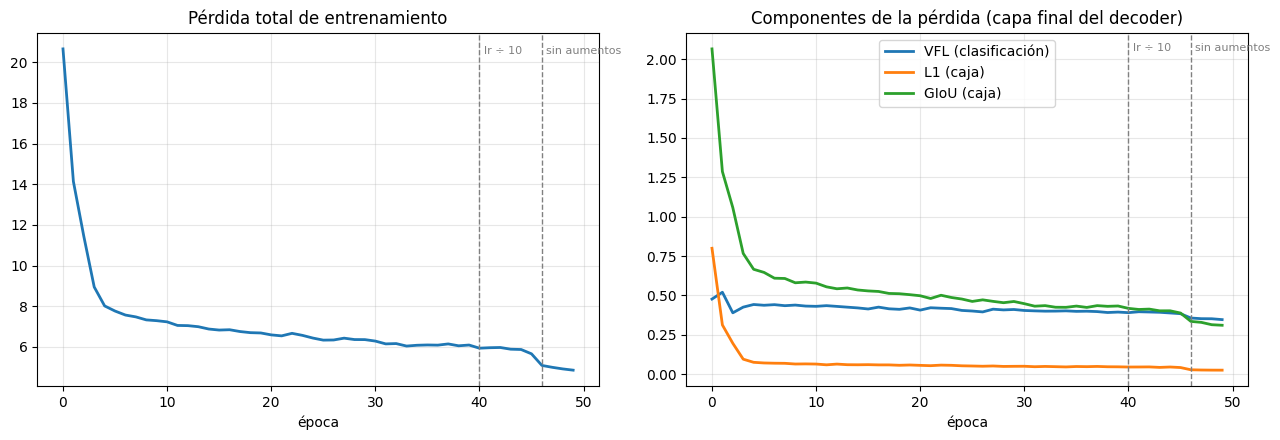

In [7]:
import matplotlib.pyplot as plt

LOG = Path(REPO) / "output" / "matriculas_r18_800" / "log.txt"
GRAFICAS = Path("graficas")
GRAFICAS.mkdir(exist_ok=True)
BAJADA_LR, FIN_AUMENTOS = 40, 46
AP, AP50, AP75, AP_S, AP_M, AP_L = range(6)   # posiciones en test_coco_eval_bbox (orden de pycocotools)

epocas = []
for linea in LOG.read_text(encoding="utf-8").splitlines():
    if linea.strip():
        epocas.append(json.loads(linea))
x = [e["epoch"] for e in epocas]
mejor = max(epocas, key=lambda e: e["test_coco_eval_bbox"][AP])


def marcas(ax):
    """Marca con líneas discontinuas la bajada del learning rate y el fin de los aumentos fuertes."""
    for ep, txt in ((BAJADA_LR, "lr ÷ 10"), (FIN_AUMENTOS, "sin aumentos")):
        ax.axvline(ep, color="gray", ls="--", lw=1)
        ax.text(ep + 0.4, ax.get_ylim()[1] * 0.97, txt, color="gray", va="top", fontsize=8)


fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
a1.plot(x, [e["train_loss"] for e in epocas], lw=2)
a1.set_title("Pérdida total de entrenamiento")
componentes = (("train_loss_vfl", "VFL (clasificación)"),
               ("train_loss_bbox", "L1 (caja)"),
               ("train_loss_giou", "GIoU (caja)"))
for clave, nombre in componentes:
    a2.plot(x, [e[clave] for e in epocas], lw=2, label=nombre)
a2.set_title("Componentes de la pérdida (capa final del decoder)")
a2.legend()
for a in (a1, a2):
    a.set_xlabel("época")
    a.grid(alpha=0.3)
    marcas(a)
fig.tight_layout()
fig.savefig(GRAFICAS / "perdidas.png", dpi=120)
plt.show()

**Lectura de las pérdidas** (cuanto más bajas, mejor; se miden sobre los datos de entrenamiento):

- **Pérdida total**: suma de todas las pérdidas del modelo (las de cada capa del decoder, las del encoder y las de *denoising*). Por eso vale entre 5 y 20 aunque cada componente sea pequeño.
- **VFL** (*Varifocal Loss*): error de **clasificación**, es decir, si cada caja es matrícula o fondo y con qué confianza.
- **L1**: error de **posición** de la caja (diferencia entre las coordenadas predichas y las reales).
- **GIoU**: error de **solape** entre la caja predicha y la real; penaliza las cajas mal encajadas.

La pérdida cae deprisa en las 5 primeras épocas (el modelo aprende la clase nueva) y luego sigue bajando despacio. Los dos escalones finales coinciden con la bajada del learning rate (época 40) y con el apagado de los aumentos fuertes (época 46). No son sobreajuste, porque las métricas de validación no empeoran, como se ve a continuación.

### 4.2 Métricas de validación

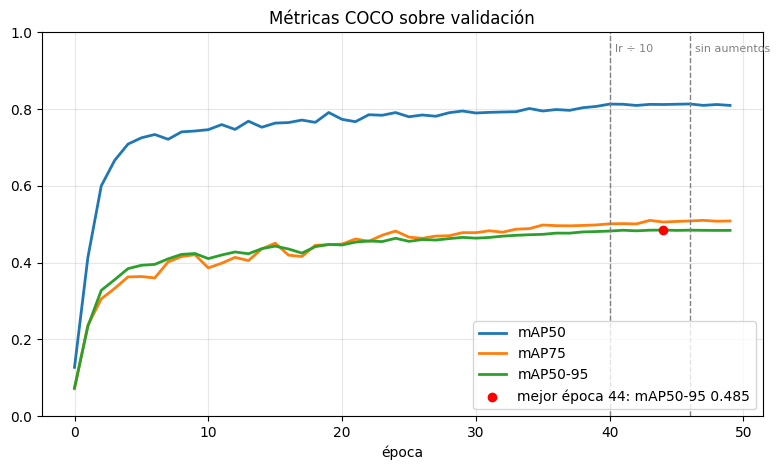

Épocas: 50 · mejor época: 44
mAP50-95 0.485 · mAP50 0.812 · mAP75 0.506 · mAP50-95 pequeñas 0.313 · medianas 0.594 · grandes 0.693


In [8]:
fig, a = plt.subplots(figsize=(8, 4.8))
for idx, nombre in ((AP50, "mAP50"), (AP75, "mAP75"), (AP, "mAP50-95")):
    a.plot(x, [e["test_coco_eval_bbox"][idx] for e in epocas], lw=2, label=nombre)
a.scatter([mejor["epoch"]], [mejor["test_coco_eval_bbox"][AP]], color="red", zorder=5,
          label=f"mejor época {mejor['epoch']}: mAP50-95 {mejor['test_coco_eval_bbox'][AP]:.3f}")
a.set_title("Métricas COCO sobre validación")
a.set_xlabel("época")
a.set_ylim(0, 1)
a.grid(alpha=0.3)
marcas(a)
a.legend(loc="lower right")
fig.tight_layout()
fig.savefig(GRAFICAS / "metricas.png", dpi=120)
plt.show()

m = mejor["test_coco_eval_bbox"]
print(f"Épocas: {len(epocas)} · mejor época: {mejor['epoch']}")
print(f"mAP50-95 {m[AP]:.3f} · mAP50 {m[AP50]:.3f} · mAP75 {m[AP75]:.3f} · "
      f"mAP50-95 pequeñas {m[AP_S]:.3f} · medianas {m[AP_M]:.3f} · grandes {m[AP_L]:.3f}")

**Lectura de las métricas** (cuanto más altas, mejor; se miden sobre imágenes que el modelo no ve al entrenar):

- **mAP50** (≈ 0,81): una detección es un acierto si solapa al menos un **50 %** (IoU ≥ 0,5) con la matrícula real. Mide si el modelo **encuentra** la matrícula.
- **mAP75** (≈ 0,51): igual, pero exige un **75 %** de solape: la caja tiene que estar muy bien ajustada.
- **mAP50-95** (≈ 0,48): la media con umbrales de IoU de 0,50 a 0,95. Es la **métrica oficial de COCO** y la que se usa para elegir la mejor época (`best.pth`).

El mAP50 supera 0,8 a partir de la época 20: casi todas las matrículas se encuentran. El mAP50-95 es más bajo porque exige cajas muy ajustadas, algo difícil en matrículas de pocos píxeles. Por tamaños se confirma: las matrículas **pequeñas** son el punto débil (0,31 frente a 0,69 en las grandes). La parada temprana no llegó a activarse, porque el modelo siguió mejorando poco a poco hasta el final.

### 4.3 Comparación con YOLO11n

Leemos las métricas de validación del entrenamiento de YOLO11n de la otra parte de la práctica (`results/model_yolo11n_detect_plates/results.csv`) y las dibujamos junto a las de RT-DETR. Las pérdidas no se comparan: cada modelo usa funciones de pérdida distintas (YOLO: box, cls y DFL; RT-DETR: VFL, L1 y GIoU) y sus valores no son comparables. La comparación definitiva se hace sobre el conjunto de test, en la sección 7.

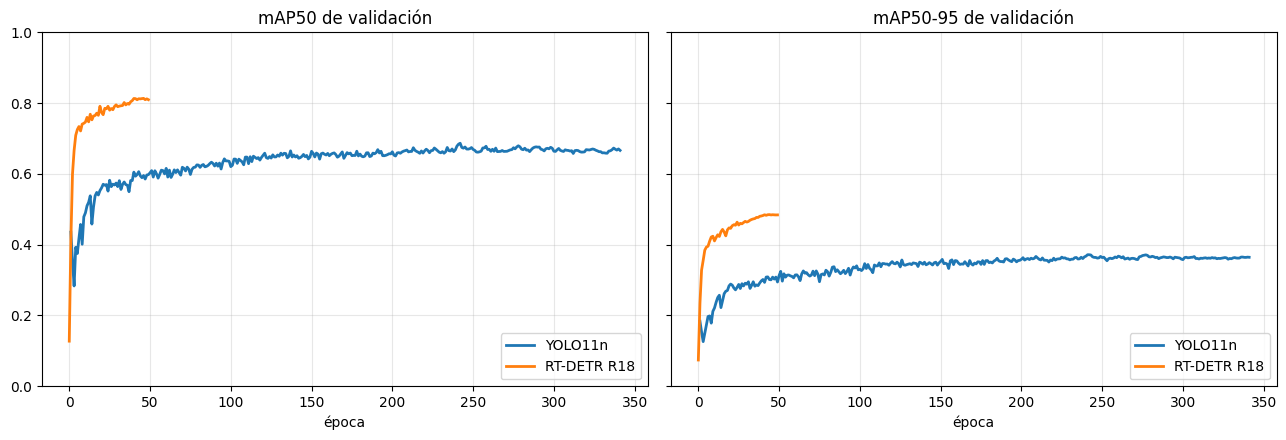

modelo       épocas mejor época  mAP50 mAP50-95
YOLO11n         341         241  0.684    0.372
RT-DETR R18      50          44  0.812    0.485


In [9]:
import csv

YOLO_CSV = Path("results/model_yolo11n_detect_plates/results.csv")
yolo = []
with open(YOLO_CSV, encoding="utf-8") as f:
    for fila in csv.DictReader(f):
        yolo.append({k.strip(): float(v) for k, v in fila.items()})   # Ultralytics deja espacios en las cabeceras

# Para cada modelo: (épocas, mAP50, mAP50-95). RT-DETR numera las épocas desde 0 y YOLO desde 1.
curvas = {
    "YOLO11n": ([e["epoch"] for e in yolo],
                [e["metrics/mAP50(B)"] for e in yolo],
                [e["metrics/mAP50-95(B)"] for e in yolo]),
    "RT-DETR R18": ([e["epoch"] for e in epocas],
                    [e["test_coco_eval_bbox"][AP50] for e in epocas],
                    [e["test_coco_eval_bbox"][AP] for e in epocas]),
}

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, k, titulo in ((ejes[0], 1, "mAP50 de validación"), (ejes[1], 2, "mAP50-95 de validación")):
    for nombre, c in curvas.items():
        ax.plot(c[0], c[k], lw=2, label=nombre)
    ax.set_title(titulo)
    ax.set_xlabel("época")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(GRAFICAS / "comparativa_yolo_rtdetr.png", dpi=120)
plt.show()

print(f"{'modelo':<12} {'épocas':>6} {'mejor época':>11} {'mAP50':>6} {'mAP50-95':>8}")
for nombre, (ep, m50, m5095) in curvas.items():
    i = max(range(len(ep)), key=lambda j: m5095[j])   # época con mejor mAP50-95
    print(f"{nombre:<12} {len(ep):>6} {int(ep[i]):>11} {m50[i]:>6.3f} {m5095[i]:>8.3f}")

**Resultado de la comparación (validación)**

| Modelo | Épocas | Mejor época | mAP50 | mAP50-95 |
|---|---:|---:|---:|---:|
| YOLO11n | 341 | 241 | 0.684 | 0.372 |
| RT-DETR R18 | 50 | 44 | **0.812** | **0.485** |

RT-DETR supera a YOLO11n en las dos métricas (+0,13 en mAP50 y +0,11 en mAP50-95) con muchas menos épocas: ya en las primeras supera el valor final de YOLO. Le ayuda partir de pesos de COCO y entrenar a 800 px frente a 640, lo que le permite ver mejor las matrículas pequeñas. A cambio es un modelo más pesado que YOLO11n.

---

## 5. Procesado del vídeo

Para cada fotograma:

1. **Detección general** con RT-DETRv2-L (COCO): personas, bicicletas, coches, motos, autobuses y camiones. Como la cámara está fija, se descartan los vehículos cuyo borde inferior queda por encima de la calzada (y < 300 px): eran objetos del parque confundidos con coches.
2. **Seguimiento** con un seguidor propio al estilo ByteTrack, para que cada objeto conserve su identificador.
3. **Matrícula**: se recorta cada vehículo y el detector de matrículas busca dentro del recorte.
4. **Conteo** del número de objetos distintos de cada clase que llegan a verse bien.
5. **Salida**: se dibujan cajas, identificadores, matrículas y totales en el vídeo, y se escribe una fila del CSV por objeto y fotograma.

### 5.1 Configuración

Todos los parámetros del procesado están juntos en esta celda para poder ajustarlos sin tocar el resto del código.

In [10]:
import itertools
import re
import time
from collections import Counter

import cv2
import numpy as np
from scipy.optimize import linear_sum_assignment

VIDEO_ENTRADA = "video_practica.MP4"
VIDEO_SALIDA = "resultado_rtdetr.mp4"
CSV_SALIDA = "resultado_rtdetr.csv"

# yml y pesos del detector de matrículas (los genera train.py)
CFG_MATRICULAS = os.path.join(REPO, "rtdetrv2_matriculas.yml")
PESOS_MATRICULAS = os.path.join(REPO, "output/matriculas_r18_800/best.pth")

FAMILIA_GENERAL, TAMANO_GENERAL = "v2", "l"
MAX_FOTOGRAMAS = None

# Detección
CONF_BAJA = 0.15
CONF_ALTA = 0.45
CONF_MATRICULA = 0.40
LADO_MIN_VEHICULO = 40
ANCHO_MIN_MATRICULA = 10
PROP_MAX_MATRICULA = 0.6
Y_MIN_SUELO = 300

# Seguimiento
EXPANSION_IOU = 0.3
MAX_PERDIDOS = 60
CONTENCION_MAX = 0.8

# Conteo: solo cuentan los objetos que se ven bien
TAM_MIN_CONTEO = 60
FOTOGRAMAS_MIN_CONTEO = 10
MIN_DETECC_MATRICULA = 2

CLASES_PERSONA = {0: "persona"}
CLASES_VEHICULO = {1: "bicicleta", 2: "coche", 3: "moto", 5: "autobus", 7: "camion"}
CLASES = {**CLASES_PERSONA, **CLASES_VEHICULO}

### 5.2 Modelos y detectores

- El detector general se carga con `load_rtdetr`, que descarga los pesos de COCO si no están.
- El de matrículas se monta a partir de nuestro yml y de `best.pth`. Se usan los pesos **EMA** (una media móvil de los pesos durante el entrenamiento, más estable) y `deploy()` deja el modelo listo para predecir.
- `detector_general` y `detector_matriculas` reciben imágenes BGR de OpenCV y devuelven cajas `x1, y1, x2, y2` en píxeles de la imagen original, gracias a que el *postprocessor* recibe su tamaño.

In [11]:
sys.path.insert(0, os.path.abspath(REPO))
from load_rtdetr import load_rtdetr
from src.core import YAMLConfig

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DEVICE)

modelo_general, post_general = load_rtdetr(family=FAMILIA_GENERAL, size=TAMANO_GENERAL, device=DEVICE)


def cargar_matriculas(cfg_path, pesos, device):
    """Construye el modelo de matrículas desde el yml y carga sus pesos. Devuelve (modelo, postprocesador, lado de entrada)."""
    cfg = YAMLConfig(cfg_path, PResNet={"pretrained": False})
    ckpt = torch.load(pesos, map_location="cpu", weights_only=False)
    if "ema" in ckpt:
        estado = ckpt["ema"]["module"]
    else:
        estado = ckpt["model"]
    cfg.model.load_state_dict(estado)
    tam = cfg.yaml_cfg.get("eval_spatial_size", [640, 640])
    return cfg.model.deploy().to(device), cfg.postprocessor.deploy().to(device), int(tam[0])


modelo_matriculas, post_matriculas, TAM_MATRICULAS = cargar_matriculas(CFG_MATRICULAS, PESOS_MATRICULAS, DEVICE)
print("Entrada del detector de matrículas:", TAM_MATRICULAS)


def a_tensor(bgr, lado):
    """Redimensiona una imagen BGR a lado×lado y la convierte en un tensor RGB con valores entre 0 y 1."""
    h, w = bgr.shape[:2]
    if max(h, w) > lado:
        interp = cv2.INTER_AREA      # reducir
    else:
        interp = cv2.INTER_LINEAR    # ampliar
    rgb = cv2.cvtColor(cv2.resize(bgr, (lado, lado), interpolation=interp), cv2.COLOR_BGR2RGB)
    return torch.from_numpy(rgb).permute(2, 0, 1).float().div(255)


@torch.no_grad()
def detector_general(frame):
    """Devuelve las cajas xyxy, confianzas y clases COCO de las personas y vehículos del fotograma."""
    h, w = frame.shape[:2]
    x = a_tensor(frame, 640)[None].to(DEVICE)
    labels, boxes, scores = post_general(modelo_general(x), torch.tensor([[w, h]], device=DEVICE))
    labels, boxes, scores = labels[0].cpu().numpy(), boxes[0].cpu().numpy(), scores[0].cpu().numpy()
    keep = (scores >= CONF_BAJA) & np.isin(labels, list(CLASES))
    return boxes[keep], scores[keep], labels[keep]


@torch.no_grad()
def detector_matriculas(recortes, lote=8):
    """Para cada recorte de vehículo devuelve (cajas, confianzas) de sus matrículas, en coordenadas del recorte."""
    salida = []
    for i in range(0, len(recortes), lote):
        grupo = recortes[i:i + lote]
        x = torch.stack([a_tensor(r, TAM_MATRICULAS) for r in grupo]).to(DEVICE)
        tams = torch.tensor([[r.shape[1], r.shape[0]] for r in grupo], device=DEVICE)
        _, boxes, scores = post_matriculas(modelo_matriculas(x), tams)
        for b, s in zip(boxes.cpu().numpy(), scores.cpu().numpy()):
            k = s >= CONF_MATRICULA
            salida.append((b[k], s[k]))
    return salida

Dispositivo: cuda
Cargando RT-DETR familia 'v2', tamaño 'l' en cuda
Load PResNet50 state_dict
Entrada del detector de matrículas: 800


### 5.3 Seguimiento

El seguimiento consiste en saber que el coche del fotograma actual es el mismo que el del anterior, para que conserve su identificador. Programamos un seguidor propio con la idea de **ByteTrack**, sin depender de Ultralytics.

#### Funciones geométricas

Primero, las operaciones con cajas que usa el seguidor:

- `matriz_iou`: el **IoU** (área compartida entre área total) de todas las parejas de cajas a la vez.
- `ampliar`: agranda las cajas un 30 % manteniendo su centro. Con cajas pequeñas, un temblor de pocos píxeles deja el IoU en 0 y la pista se pierde; ampliadas, siguen solapando (*buffered IoU*).
- `quitar_duplicados`: aunque RT-DETR no necesita NMS, a veces un mismo objeto sale dos veces, como coche y como camión (IoU alto), o como una caja entera y otra que solo cubre un trozo. Se queda la de más confianza y se quitan los trozos.

In [12]:
def matriz_iou(a, b):
    """IoU entre cada caja de a (filas) y cada caja de b (columnas), en formato xyxy."""
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    a, b = np.asarray(a)[:, None, :], np.asarray(b)[None, :, :]
    ix = np.clip(np.minimum(a[..., 2], b[..., 2]) - np.maximum(a[..., 0], b[..., 0]), 0, None)
    iy = np.clip(np.minimum(a[..., 3], b[..., 3]) - np.maximum(a[..., 1], b[..., 1]), 0, None)
    inter = ix * iy
    area_a = (a[..., 2] - a[..., 0]) * (a[..., 3] - a[..., 1])
    area_b = (b[..., 2] - b[..., 0]) * (b[..., 3] - b[..., 1])
    return inter / np.maximum(area_a + area_b - inter, 1e-6)


def ampliar(cajas, f=EXPANSION_IOU):
    """Agranda cada caja un factor f manteniendo su centro (buffered IoU)."""
    c = np.asarray(cajas, float).reshape(-1, 4)
    dx = (c[:, 2] - c[:, 0]) * f / 2
    dy = (c[:, 3] - c[:, 1]) * f / 2
    return np.stack([c[:, 0] - dx, c[:, 1] - dy, c[:, 2] + dx, c[:, 3] + dy], axis=1)


def matriz_contencion(a, b):
    """Fracción del área de cada caja de a que queda dentro de cada caja de b."""
    a, b = np.asarray(a)[:, None, :], np.asarray(b)[None, :, :]
    ix = np.clip(np.minimum(a[..., 2], b[..., 2]) - np.maximum(a[..., 0], b[..., 0]), 0, None)
    iy = np.clip(np.minimum(a[..., 3], b[..., 3]) - np.maximum(a[..., 1], b[..., 1]), 0, None)
    area_a = (a[..., 2] - a[..., 0]) * (a[..., 3] - a[..., 1])
    return ix * iy / np.maximum(area_a, 1e-6)


def quitar_duplicados(cajas, confs, clases, umbral=0.7, contencion=CONTENCION_MAX):
    """
    Elimina las detecciones repetidas de un mismo objeto:
    1. cajas casi iguales (IoU > umbral), quedándose con la de más confianza;
    2. cajas que quedan casi enteras (≥ contencion) dentro de otra más grande: son un trozo del mismo objeto.
    """
    if len(cajas) == 0:
        return cajas, confs, clases
    orden = np.argsort(-confs)   # de más a menos confianza
    iou = matriz_iou(cajas, cajas)
    fuera = np.zeros(len(cajas), bool)
    for pos, i in enumerate(orden):
        if fuera[i]:
            continue
        resto = orden[pos + 1:]
        fuera[resto[iou[i, resto] > umbral]] = True

    dentro = matriz_contencion(cajas, cajas)
    area = (cajas[:, 2] - cajas[:, 0]) * (cajas[:, 3] - cajas[:, 1])
    for i in range(len(cajas)):
        mayores = (area > area[i]) & ~fuera
        if np.any(dentro[i, mayores] >= contencion):
            fuera[i] = True
    return cajas[~fuera], confs[~fuera], clases[~fuera]

#### La pista: un objeto seguido

Cada objeto seguido es una `Pista`, que guarda:

- su **estado** (centro, ancho y alto) y su **velocidad**, que se actualizan con un filtro **alfa-beta**: una versión sencilla del filtro de Kalman que corrige la posición con un 70 % de lo observado y la velocidad con un 25 %;
- los **votos de su clase**: cada detección vota por su clase con un peso igual a su confianza, así un coche que en algún fotograma se confunde con un camión sigue contando como coche;
- lo necesario para el conteo: el mayor tamaño alcanzado, en cuántos fotogramas se ha detectado y en cuántos con matrícula.

Una pista es **quieta** si se ha visto al menos 1 s (25 fotogramas) y su centro apenas se ha movido: un coche aparcado o una persona parada. Una pista quieta no se desplaza por inercia, porque su "velocidad" solo sería el temblor de la caja.

In [13]:
class Pista:
    """Un objeto seguido a lo largo del vídeo."""

    ALFA, BETA = 0.7, 0.25

    def __init__(self, caja, conf, clase):
        self.estado = self._a_cxcywh(caja)
        self.vel = np.zeros(4)
        self.id = None
        self.aciertos, self.perdidos = 1, 0
        self.votos = Counter({int(clase): float(conf)})
        self.caja, self.conf = np.asarray(caja, float), float(conf)
        self.lado_max = float(max(self.estado[2:]))
        self.cmin, self.cmax = self.estado[:2].copy(), self.estado[:2].copy()
        self.visto = True
        self.con_matricula = 0

    @staticmethod
    def _a_cxcywh(c):
        """Pasa una caja de x1, y1, x2, y2 a centro x, centro y, ancho, alto."""
        return np.array([(c[0] + c[2]) / 2, (c[1] + c[3]) / 2, c[2] - c[0], c[3] - c[1]], float)

    def predecir(self):
        """Estima dónde estará la pista en el fotograma nuevo."""
        if not self.quieta:
            self.estado = self.estado + self.vel
        self.estado[2:] = np.maximum(self.estado[2:], 1.0)
        self.visto = False

    def corregir(self, caja, conf, clase):
        """Actualiza la pista con la detección que se le ha asignado."""
        nueva = self._a_cxcywh(caja)
        resid = nueva - self.estado
        self.estado = self.estado + self.ALFA * resid
        self.vel = self.vel + self.BETA * resid
        self.caja, self.conf = np.asarray(caja, float), float(conf)
        self.votos[int(clase)] += float(conf)
        self.lado_max = max(self.lado_max, float(max(nueva[2:])))
        self.cmin = np.minimum(self.cmin, nueva[:2])
        self.cmax = np.maximum(self.cmax, nueva[:2])
        self.aciertos += 1
        self.perdidos = 0
        self.visto = True

    def despertar(self, caja, conf, clase):
        """Recupera una pista dormida en su sitio, sin velocidad acumulada."""
        self.estado, self.vel = self._a_cxcywh(caja), np.zeros(4)
        self.corregir(caja, conf, clase)

    @property
    def xyxy(self):
        """Caja estimada por el filtro, en formato x1, y1, x2, y2."""
        cx, cy, w, h = self.estado
        return np.array([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2])

    @property
    def clase(self):
        """Clase con más votos."""
        return self.votos.most_common(1)[0][0]

    @property
    def quieta(self):
        """Vista al menos 1 s y con un centro que se ha movido menos de medio tamaño."""
        recorrido = float(np.max(self.cmax - self.cmin))
        return self.aciertos >= 25 and recorrido < 0.5 * self.lado_max

    @property
    def contable(self):
        """Solo cuenta si se ha visto bien: suficientemente grande y en suficientes fotogramas."""
        return self.lado_max >= TAM_MIN_CONTEO and self.aciertos >= FOTOGRAMAS_MIN_CONTEO

#### El seguidor

`Seguidor.actualizar` recibe las detecciones de un fotograma y las reparte entre las pistas:

1. **Predicción**: cada pista avanza según su velocidad.
2. **Primera pasada, detecciones fuertes** (confianza ≥ 0,45): se emparejan con todas las pistas con el **algoritmo húngaro** (`linear_sum_assignment`), que busca el reparto global con más IoU.
3. **Segunda pasada, detecciones débiles**: solo sirven para mantener las pistas que no se emparejaron; nunca crean pistas nuevas. Es la idea clave de ByteTrack: un coche medio tapado da una detección débil, pero sigue siendo el mismo coche.
4. **Reidentificación**: una detección fuerte sin pareja que aparece en el sitio de una pista **quieta** que se perdió (un coche aparcado tapado un momento por otro que pasa) recupera ese identificador, en lugar de contarse otra vez. Sin esto, un mismo coche aparcado llegó a tener 25 IDs.
5. **Pistas nuevas**: el resto de detecciones fuertes crean una pista, que solo recibe identificador tras **3 aciertos**. Si al confirmarse resulta que ocupa el sitio de un objeto quieto que ya tenía ID, se considera el mismo objeto.
6. **Limpieza**: una pista con ID sobrevive 60 fotogramas sin detección; si estaba quieta, en vez de borrarse pasa a "dormida".

Hay un seguidor para personas y otro para vehículos, que comparten el contador de IDs.

In [14]:
class Seguidor:
    """Asociación de detecciones a pistas en dos pasadas, al estilo ByteTrack."""

    def __init__(self, contador, conf_alta=CONF_ALTA, iou_alta=0.3, iou_baja=0.5,
                 min_aciertos=3, max_perdidos=MAX_PERDIDOS):
        self.contador = contador
        self.conf_alta, self.iou_alta, self.iou_baja = conf_alta, iou_alta, iou_baja
        self.min_aciertos, self.max_perdidos = min_aciertos, max_perdidos
        self.activas, self.confirmadas = [], []
        self.dormidas = []

    @staticmethod
    def _asociar(pistas, cajas, umbral):
        """
        Empareja pistas y cajas maximizando el IoU (algoritmo húngaro).
        Devuelve (parejas, índices de pistas sin pareja, índices de cajas sin pareja).
        """
        if not pistas or len(cajas) == 0:
            return [], list(range(len(pistas))), list(range(len(cajas)))
        iou = matriz_iou(ampliar([p.xyxy for p in pistas]), ampliar(cajas))
        filas, cols = linear_sum_assignment(1 - iou)
        pares = []
        for f, c in zip(filas, cols):
            if iou[f, c] >= umbral:
                pares.append((f, c))
        usadas_f = {f for f, _ in pares}
        usadas_c = {c for _, c in pares}
        libres_pistas = [i for i in range(len(pistas)) if i not in usadas_f]
        libres_cajas = [j for j in range(len(cajas)) if j not in usadas_c]
        return pares, libres_pistas, libres_cajas

    def _quieta_en(self, caja, umbral=0.5):
        """Pista quieta con identificador (activa o dormida) que ocupa el mismo sitio que caja, o None."""
        candidatas = [q for q in self.activas + self.dormidas if q.id is not None and q.quieta]
        if not candidatas:
            return None
        iou = matriz_iou([q.caja for q in candidatas], [caja])[:, 0]
        k = int(np.argmax(iou))
        if iou[k] >= umbral:
            return candidatas[k]
        return None

    def actualizar(self, cajas, confs, clases):
        """Procesa las detecciones de un fotograma. Devuelve las pistas con ID vistas en este fotograma."""
        for p in self.activas:
            p.predecir()
        alta = confs >= self.conf_alta
        ca, sa, la = cajas[alta], confs[alta], clases[alta]
        cb, sb, lb = cajas[~alta], confs[~alta], clases[~alta]

        # 1.ª pasada: detecciones fuertes contra todas las pistas
        pares, libres, nuevas = self._asociar(self.activas, ca, self.iou_alta)
        for f, c in pares:
            self.activas[f].corregir(ca[c], sa[c], la[c])

        # 2.ª pasada: detecciones débiles solo para no perder pistas existentes
        resto = [self.activas[i] for i in libres]
        pares2, libres2, _ = self._asociar(resto, cb, self.iou_baja)
        for f, c in pares2:
            resto[f].corregir(cb[c], sb[c], lb[c])
        for i in libres2:
            resto[i].perdidos += 1

        # Reidentificación: detección nueva en el sitio de una pista quieta que se perdió
        if self.dormidas and nuevas:
            iou = matriz_iou([p.caja for p in self.dormidas], ca[nuevas])
            filas, cols = linear_sum_assignment(1 - iou)
            despiertas = {(f, c) for f, c in zip(filas, cols) if iou[f, c] >= 0.5}
            for f, c in despiertas:
                j = nuevas[c]
                self.dormidas[f].despertar(ca[j], sa[j], la[j])
                self.activas.append(self.dormidas[f])
            usadas_f = {f for f, _ in despiertas}
            usadas_c = {c for _, c in despiertas}
            self.dormidas = [p for i, p in enumerate(self.dormidas) if i not in usadas_f]
            nuevas = [j for c, j in enumerate(nuevas) if c not in usadas_c]

        for j in nuevas:
            self.activas.append(Pista(ca[j], sa[j], la[j]))

        # Confirmación
        for p in list(self.activas):
            if p.id is not None or p.aciertos < self.min_aciertos:
                continue
            vieja = self._quieta_en(p.caja)
            if vieja is None:
                p.id = next(self.contador)
                self.confirmadas.append(p)
                continue
            self.activas.remove(p)
            if not vieja.visto:
                vieja.despertar(p.caja, p.conf, p.clase)
            if vieja in self.dormidas:
                self.dormidas.remove(vieja)
                self.activas.append(vieja)

        # Limpieza: las pistas sin ID no sobreviven ni un fotograma perdidas; las quietas pasan a dormidas
        vivas = []
        for p in self.activas:
            if p.id is not None:
                limite = self.max_perdidos
            else:
                limite = 0
            if p.perdidos <= limite:
                vivas.append(p)
            elif p.id is not None and p.quieta:
                self.dormidas.append(p)
        self.activas = vivas

        visibles = []
        for p in self.activas:
            if p.id is not None and p.visto:
                visibles.append(p)
        return visibles

### 5.4 Matrículas, conteo y CSV

Funciones auxiliares del bucle principal:

- `limpiar_etiqueta` y `a_id` usan **expresiones regulares** para dejar las etiquetas y los IDs del CSV en un formato limpio. RT-DETR devuelve números (arrays de NumPy), no texto, así que la regex solo hace falta aquí y en la comprobación final del CSV.
- `recorte_cuadrado` recorta cada vehículo con un 10 % de margen y casi cuadrado, para no deformar la matrícula al redimensionarlo a 800×800.
- `elegir_matricula` se queda con la candidata más segura cuyo centro cae dentro del vehículo y que mide entre 10 px y el 60 % del ancho del vehículo. Una matrícula real ocupa un 10-40 % del ancho; las cajas mayores eran errores (este filtro quitó unas 800 matrículas falsas).
- `totales` cuenta las pistas distintas que cumplen el criterio de conteo. Contarlas todas daba cifras muy altas (la primera versión contaba 294 coches), sobre todo por los coches del horizonte, que pierden y recuperan el ID; por eso solo cuentan los objetos que llegan a verse bien: **lado mayor ≥ 60 px y detectados en ≥ 10 fotogramas**. Una matrícula cuenta si su vehículo cumple el criterio y se ha visto en al menos 2 fotogramas.

Formato del CSV: `fotograma, tipo_objeto, confianza, identificador_tracking, x1, y1, x2, y2, matrícula_en_su_caso, confianza_mat, mx1, my1, mx2, my2, texto_matricula`. Para los vehículos sin matrícula detectada `matrícula_en_su_caso = no`; para las personas esas columnas quedan vacías. `texto_matricula` queda vacío: el OCR se ha desarrollado en la alternativa YOLO.

In [15]:
CABECERA = ["fotograma", "tipo_objeto", "confianza", "identificador_tracking", "x1", "y1", "x2", "y2",
            "matrícula_en_su_caso", "confianza_mat", "mx1", "my1", "mx2", "my2", "texto_matricula"]


def limpiar_etiqueta(nombre):
    """'Traffic Light' -> 'traffic_light': minúsculas, y todo lo que no sea letra o número pasa a '_'."""
    return re.sub(r"[^a-z0-9_]+", "_", str(nombre).strip().lower()).strip("_")


def a_id(valor):
    """Saca el número de un ID venga como venga: 12, 12.0, '#12', 'id: 12', 'tensor([12.])' -> 12."""
    m = re.search(r"\d+", str(valor))
    if m:
        return int(m.group())
    return ""


def caja_entera(caja, W, H):
    """Redondea una caja xyxy a enteros y la recorta a los bordes del fotograma (0..W-1, 0..H-1)."""
    x1, y1, x2, y2 = (int(round(float(v))) for v in caja)
    return max(x1, 0), max(y1, 0), min(x2, W - 1), min(y2, H - 1)


def recorte_cuadrado(frame, caja, margen=0.10):
    """Recorte casi cuadrado del vehículo, con un margen de contexto. Devuelve (recorte, esquina superior izquierda)."""
    H, W = frame.shape[:2]
    x1, y1, x2, y2 = caja
    lado = max(x2 - x1, y2 - y1) * (1 + 2 * margen)
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    rx1, ry1 = max(0, int(cx - lado / 2)), max(0, int(cy - lado / 2))
    rx2, ry2 = min(W, int(cx + lado / 2)), min(H, int(cy + lado / 2))
    return frame[ry1:ry2, rx1:rx2], (rx1, ry1)


def elegir_matricula(cajas, confs, origen, caja_vehiculo):
    """Mejor candidata cuyo centro cae dentro del vehículo y con un ancho razonable. Devuelve (caja_en_fotograma, conf) o None."""
    ancho_vehiculo = caja_vehiculo[2] - caja_vehiculo[0]
    mejor = None
    for b, s in zip(cajas, confs):
        # Del recorte al fotograma: se suma la posición del recorte
        m = np.array([b[0] + origen[0], b[1] + origen[1], b[2] + origen[0], b[3] + origen[1]], float)
        ancho = m[2] - m[0]
        if ancho < ANCHO_MIN_MATRICULA or ancho > PROP_MAX_MATRICULA * ancho_vehiculo:
            continue
        cx, cy = (m[0] + m[2]) / 2, (m[1] + m[3]) / 2
        dentro = caja_vehiculo[0] <= cx <= caja_vehiculo[2] and caja_vehiculo[1] <= cy <= caja_vehiculo[3]
        if dentro and (mejor is None or s > mejor[1]):
            mejor = (m, float(s))
    return mejor


def color_id(i):
    """Color fijo para cada ID, para que un objeto tenga siempre el mismo color en el vídeo."""
    return tuple(int(c) for c in np.random.RandomState(int(i)).randint(60, 255, 3))


def totales(seguidores):
    """Total por clase = pistas distintas que cumplen el criterio de conteo (Pista.contable)."""
    cuenta = Counter()
    for s in seguidores:
        for p in s.confirmadas:
            if not p.contable:
                continue
            cuenta[CLASES[p.clase]] += 1
            if p.con_matricula >= MIN_DETECC_MATRICULA:
                cuenta["matricula"] += 1
    return cuenta


def dibujar_totales(img, cuenta):
    """Panel negro con los totales en la esquina superior izquierda."""
    filas = [f"{k}: {v}" for k, v in sorted(cuenta.items())]
    cv2.rectangle(img, (8, 8), (200, 22 + 24 * max(len(filas), 1)), (0, 0, 0), -1)
    for n, txt in enumerate(filas):
        cv2.putText(img, txt, (16, 32 + 24 * n), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)

### 5.5 Bucle principal

`procesar_video` lee el vídeo fotograma a fotograma y aplica los pasos anteriores en orden. El parámetro `ocr` es una función opcional `recorte_bgr -> texto`: es el punto donde se conectaría un reconocedor de texto para rellenar `texto_matricula`.

In [16]:
def procesar_video(entrada, salida, ruta_csv, det_general, det_matriculas, ocr=None, max_fotogramas=None):
    """Procesa el vídeo completo: escribe el vídeo anotado y el CSV, y devuelve los totales por clase."""
    cap = cv2.VideoCapture(entrada)
    if not cap.isOpened():
        raise FileNotFoundError(f"No se puede abrir {entrada}")
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    W, H = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    escritor = cv2.VideoWriter(salida, cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))

    ids = itertools.count(1)   # contador compartido: personas y vehículos nunca repiten ID
    personas, vehiculos = Seguidor(ids), Seguidor(ids)
    t0, n = time.time(), 0

    with open(ruta_csv, "w", newline="", encoding="utf-8-sig") as f:
        out = csv.writer(f)
        out.writerow(CABECERA)
        while max_fotogramas is None or n < max_fotogramas:
            ok, frame = cap.read()
            if not ok:
                break

            # 1) Detección de personas y vehículos; los vehículos, solo sobre la calzada
            cajas, confs, clases = det_general(frame)
            es_persona = np.isin(clases, list(CLASES_PERSONA))
            valida = es_persona | (cajas[:, 3] >= Y_MIN_SUELO)
            cajas, confs, clases, es_persona = cajas[valida], confs[valida], clases[valida], es_persona[valida]

            # 2) Seguimiento: un seguidor por grupo
            pp = personas.actualizar(*quitar_duplicados(cajas[es_persona], confs[es_persona], clases[es_persona]))
            pv = vehiculos.actualizar(*quitar_duplicados(cajas[~es_persona], confs[~es_persona], clases[~es_persona]))

            # 3) Matrículas: se buscan dentro del recorte de cada vehículo suficientemente grande
            con_recorte, recortes, origenes = [], [], []
            for p in pv:
                if min(p.caja[2] - p.caja[0], p.caja[3] - p.caja[1]) >= LADO_MIN_VEHICULO:
                    r, o = recorte_cuadrado(frame, p.caja)
                    if r.size:
                        con_recorte.append(p)
                        recortes.append(r)
                        origenes.append(o)
            matriculas = {}
            if recortes:
                for p, o, (bb, ss) in zip(con_recorte, origenes, det_matriculas(recortes)):
                    m = elegir_matricula(bb, ss, o, p.caja)
                    if m is not None:
                        matriculas[p.id] = m
                        p.con_matricula += 1

            # 4) Una fila de CSV y un dibujo por objeto seguido
            lienzo = frame.copy()
            for p in pp + pv:
                nombre = limpiar_etiqueta(CLASES[p.clase])
                x1, y1, x2, y2 = caja_entera(p.caja, W, H)
                fila = [n, nombre, f"{p.conf:.4f}", a_id(p.id), x1, y1, x2, y2]
                if p in pv and p.id in matriculas:
                    caja_m, mc = matriculas[p.id]
                    mx1, my1, mx2, my2 = caja_entera(caja_m, W, H)
                    texto = ocr(frame[my1:my2 + 1, mx1:mx2 + 1]) if ocr else ""
                    fila += ["si", f"{mc:.4f}", mx1, my1, mx2, my2, texto]
                    cv2.rectangle(lienzo, (mx1, my1), (mx2, my2), (0, 255, 255), 2)
                    cv2.putText(lienzo, f"{texto or 'matricula'} {mc:.2f}", (mx1, max(my1 - 4, 12)),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 255), 1)
                elif p in pv:
                    fila += ["no", "", "", "", "", "", ""]   # vehículo sin matrícula detectada
                else:
                    fila += ["", "", "", "", "", "", ""]     # persona: columnas de matrícula vacías
                out.writerow(fila)
                c = color_id(p.id)
                cv2.rectangle(lienzo, (x1, y1), (x2, y2), c, 2)
                cv2.putText(lienzo, f"{nombre} #{p.id} {p.conf:.2f}", (x1, max(y1 - 6, 14)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.55, c, 2)

            # 5) Totales en pantalla y fotograma al vídeo de salida
            dibujar_totales(lienzo, totales([personas, vehiculos]))
            escritor.write(lienzo)
            n += 1
            if n % 500 == 0:
                print(f"{n} fotogramas · {n / (time.time() - t0):.2f} fps")

    cap.release()
    escritor.release()
    resultado = totales([personas, vehiculos])
    print("Fotogramas procesados:", n)
    print("Totales:", dict(sorted(resultado.items())))
    return resultado

### 5.6 Ejecución

El procesado del vídeo completo (2.832 fotogramas) tarda unos 8 minutos en la RTX 3050.

In [17]:
conteo = procesar_video(VIDEO_ENTRADA, VIDEO_SALIDA, CSV_SALIDA, detector_general, detector_matriculas,
                        max_fotogramas=MAX_FOTOGRAMAS)
conteo

500 fotogramas · 2.94 fps
1000 fotogramas · 1.82 fps
1500 fotogramas · 2.35 fps
2000 fotogramas · 2.74 fps
2500 fotogramas · 3.10 fps
Fotogramas procesados: 2832
Totales: {'autobus': 2, 'bicicleta': 1, 'coche': 60, 'matricula': 43, 'moto': 3, 'persona': 55}


Counter({'coche': 60,
         'persona': 55,
         'matricula': 43,
         'moto': 3,
         'autobus': 2,
         'bicicleta': 1})

### Análisis de los resultados del vídeo

El panel del vídeo y la salida anterior dan **60 coches, 55 personas, 43 matrículas, 3 motos, 2 autobuses y 1 bicicleta**. Para validarlo revisamos el vídeo a ojo:

- Los **coches que circulan** coinciden casi exactamente: 29 contados frente a unos 30 reales.
- Los **coches aparcados** se siguen contando algo de más: aunque la reidentificación de pistas quietas evita la mayoría de duplicados, un coche que queda tapado mucho tiempo puede recibir un ID nuevo.
- El **autobús** se cuenta dos veces, porque cambia mucho de tamaño al alejarse y pierde su identificador.
- Con el filtro de la calzada desapareció un "coche" falso del parque de la izquierda, y casi todos los vehículos cercanos tienen su matrícula detectada.

---

## 6. Comprobación del CSV

Comprobamos con expresiones regulares que la cabecera es la pedida y que **todas** las filas tienen el formato esperado según su caso: persona (columnas de matrícula vacías), vehículo sin matrícula (`no`) o vehículo con matrícula (`si` con su confianza y su caja).

In [18]:
ENTERO, CONF = r"\d+", r"[01]\.\d{4}"
TIPOS = "|".join(limpiar_etiqueta(v) for v in CLASES.values())
FILA_OK = re.compile(
    rf"^{ENTERO},({TIPOS}),{CONF},{ENTERO},{ENTERO},{ENTERO},{ENTERO},{ENTERO},"
    rf"(si,{CONF},-?{ENTERO},-?{ENTERO},{ENTERO},{ENTERO},[^,]*"
    rf"|no,,,,,,|,,,,,,)$"
)

with open(CSV_SALIDA, encoding="utf-8-sig") as f:
    lineas = f.read().splitlines()

assert lineas[0] == ",".join(CABECERA), f"Cabecera distinta: {lineas[0]}"
malas = []
for i, linea in enumerate(lineas[1:], 2):
    if not FILA_OK.match(linea):
        malas.append((i, linea))
print(f"{len(lineas) - 1} filas, {len(malas)} con formato incorrecto")
for i, linea in malas[:10]:
    print(f"  línea {i}: {linea}")

# IDs distintos por tipo de objeto en el CSV
ids_por_tipo = {}
for linea in lineas[1:]:
    campos = linea.split(",")
    ids_por_tipo.setdefault(campos[1], set()).add(campos[3])
print("IDs distintos en el CSV:", {k: len(v) for k, v in sorted(ids_por_tipo.items())})

36733 filas, 0 con formato incorrecto
IDs distintos en el CSV: {'autobus': 3, 'bicicleta': 4, 'coche': 150, 'moto': 6, 'persona': 105}


Todas las filas tienen el formato correcto. El CSV guarda **todos** los objetos seguidos, también los lejanos que no cumplen el criterio de conteo; por eso aparecen más identificadores distintos que en el panel de totales (por ejemplo, 150 de coche frente a los 60 contados).

---

## 7. Evaluación en test: YOLO11n frente a RT-DETR

Para el extra de comparar las dos alternativas se evalúan **los dos detectores de matrículas sobre las mismas 385 imágenes de test (872 matrículas)**, que ninguno de los dos vio al entrenar, y con **el mismo código**: las funciones `iou` y `evaluar_predicciones` se copian sin cambios del cuaderno de YOLO (`VC_P4_YOLO_OCR.ipynb`) y se sigue su mismo protocolo:

- predicciones con confianza ≥ 0,001 (hasta 300 por imagen) para calcular **AP50** y **mAP50-95** (AP con 101 niveles de recall; mAP con umbrales de IoU de 0,50 a 0,95);
- **precisión, recall y F1** con IoU 0,5 y el umbral de confianza que usa cada modelo en el vídeo (YOLO: 0,25; RT-DETR: 0,40);
- cada modelo recibe la imagen completa a su resolución de entrenamiento (YOLO 640 px, RT-DETR 800 px).

Como referencia se usan las anotaciones de `dataset_1920`: son las mismas cajas que en el dataset original, pero corregidas en las fotos con orientación EXIF (sección 2). Las imágenes ya están enderezadas y sin EXIF, así que los dos modelos ven exactamente los mismos píxeles.

### 7.1 Funciones de evaluación y referencias

In [19]:
from ultralytics import YOLO

# Pesos del detector de matrículas YOLO11n (parte de YOLO de la práctica)
PESOS_YOLO = None
for ruta_pesos in ("results/model_yolo11n_detect_plates/weights/best.pt", "best.pt"):
    if os.path.exists(ruta_pesos):
        PESOS_YOLO = ruta_pesos
        break
CONF_YOLO = 0.25
DATASET_TEST = Path("dataset_1920")


def iou(a, b):
    inter = max(0, min(a[2], b[2]) - max(a[0], b[0])) * max(0, min(a[3], b[3]) - max(a[1], b[1]))
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def evaluar_predicciones(predicciones, referencias, umbral_iou):
    usadas = {nombre: set() for nombre in referencias}
    tp, detalles = [], []
    for p in sorted(predicciones, key=lambda p: p["conf"], reverse=True):
        nombre = p["imagen"]
        libres = [j for j in range(len(referencias[nombre])) if j not in usadas[nombre]]
        mejor = max(
            libres, key=lambda j: iou(p["box"], referencias[nombre][j]["box"]), default=None
        )
        solape = iou(p["box"], referencias[nombre][mejor]["box"]) if mejor is not None else 0
        correcto = mejor is not None and solape >= umbral_iou
        if correcto:
            usadas[nombre].add(mejor)
        tp.append(int(correcto))
        detalles.append(
            {
                "imagen": nombre,
                "confianza": p["conf"],
                "resultado": "TP" if correcto else "FP",
                "indice_referencia": mejor if correcto else "",
                "iou": solape,
                "texto_referencia": referencias[nombre][mejor]["text"] if correcto else "",
            }
        )
    total = sum(len(r) for r in referencias.values())
    tp_acum = np.cumsum(tp)
    fp_acum = np.arange(1, len(tp) + 1) - tp_acum
    precision = tp_acum / np.maximum(tp_acum + fp_acum, 1)
    recall = tp_acum / max(total, 1)
    ap = (
        np.mean([np.max(precision[recall >= nivel], initial=0) for nivel in np.linspace(0, 1, 101)])
        if total
        else None
    )
    return ap, detalles


coco_test = json.loads((DATASET_TEST / "annotations" / "test_coco.json").read_text(encoding="utf-8"))
info = {im["id"]: (im["file_name"], im["width"], im["height"]) for im in coco_test["images"]}
referencias = {nombre: [] for nombre, _, _ in info.values()}
for a in coco_test["annotations"]:
    nombre, w, h = info[a["image_id"]]
    x, y, bw, bh = a["bbox"]
    referencias[nombre].append({"box": (x / w, y / h, (x + bw) / w, (y + bh) / h), "text": a.get("plate_text", "")})
rutas = [DATASET_TEST / "test" / "images" / nombre for nombre in referencias]
print(f"Test: {len(rutas)} imágenes, {sum(len(r) for r in referencias.values())} matrículas")

Test: 385 imágenes, 872 matrículas


### 7.2 Predicción y métricas de cada modelo

Las dos funciones de predicción devuelven lo mismo, cajas normalizadas y confianzas, para que la evaluación sea idéntica. `evaluar_modelo` predice todas las imágenes de test, mide el tiempo de cada una en la GPU (preproceso, red y postproceso; se toma la mediana y se descartan 5 imágenes de calentamiento) y calcula las métricas.

In [20]:
modelo_yolo = YOLO(PESOS_YOLO)


def predecir_yolo(bgr):
    """Matrículas según YOLO11n: (cajas xyxy normalizadas, confianzas)."""
    r = modelo_yolo.predict(bgr, conf=0.001, iou=0.7, max_det=300, imgsz=640, device=DEVICE, verbose=False)[0]
    return r.boxes.xyxyn.cpu().numpy(), r.boxes.conf.cpu().numpy()


@torch.no_grad()
def predecir_rtdetr(bgr):
    """Matrículas según RT-DETR: (cajas xyxy normalizadas, confianzas)."""
    h, w = bgr.shape[:2]
    x = a_tensor(bgr, TAM_MATRICULAS)[None].to(DEVICE)
    _, cajas, confs = post_matriculas(modelo_matriculas(x), torch.tensor([[w, h]], device=DEVICE))
    return cajas[0].cpu().numpy() / np.array([w, h, w, h]), confs[0].cpu().numpy()


def sincronizar():
    """Espera a que la GPU termine, para que el cronómetro mida el trabajo real."""
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def evaluar_modelo(predecir, conf_operativa):
    """Predice todo el test con `predecir` y devuelve un diccionario con sus métricas y su tiempo por imagen."""
    imagenes = [cv2.imread(str(r)) for r in rutas]
    for img in imagenes[:5]:   # calentamiento de la GPU, no se cronometra
        predecir(img)

    predicciones, tiempos = [], []
    for ruta, img in zip(rutas, imagenes):
        sincronizar()
        t = time.perf_counter()
        cajas, confs = predecir(img)
        sincronizar()
        tiempos.append(time.perf_counter() - t)
        for c, s in zip(cajas, confs):
            if s >= 0.001:
                predicciones.append({"imagen": ruta.name, "box": tuple(float(v) for v in c), "conf": float(s)})

    # AP con cada umbral de IoU de 0,50 a 0,95: el primero es AP50 y la media es mAP50-95
    aps = []
    for umbral in np.linspace(0.5, 0.95, 10):
        aps.append(evaluar_predicciones(predicciones, referencias, umbral)[0])

    # Precisión, recall y F1 con el umbral de confianza que usa el modelo en el vídeo
    operativas = [p for p in predicciones if p["conf"] >= conf_operativa]
    _, detalle = evaluar_predicciones(operativas, referencias, 0.5)
    tp = sum(1 for d in detalle if d["resultado"] == "TP")
    fp = len(detalle) - tp
    fn = sum(len(r) for r in referencias.values()) - tp
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    if precision + recall > 0:
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = 0.0

    return {"AP50": aps[0], "mAP50-95": float(np.mean(aps)), "conf": conf_operativa,
            "TP": tp, "FP": fp, "FN": fn, "precisión": precision, "recall": recall, "F1": f1,
            "ms/imagen": 1000 * float(np.median(tiempos))}


resultados_test = {
    "YOLO11n": evaluar_modelo(predecir_yolo, CONF_YOLO),
    "RT-DETR R18": evaluar_modelo(predecir_rtdetr, CONF_MATRICULA),
}

columnas = ["AP50", "mAP50-95", "conf", "TP", "FP", "FN", "precisión", "recall", "F1", "ms/imagen"]
print(f"{'modelo':<12}" + "".join(f"{c:>10}" for c in columnas))
for nombre, r in resultados_test.items():
    valores = ""
    for c in columnas:
        if isinstance(r[c], int):
            valores += f"{r[c]:>10}"
        else:
            valores += f"{r[c]:>10.3f}"
    print(f"{nombre:<12}" + valores)

modelo            AP50  mAP50-95      conf        TP        FP        FN precisión    recall        F1 ms/imagen
YOLO11n          0.701     0.389     0.250       601       100       271     0.857     0.689     0.764     9.248
RT-DETR R18      0.828     0.476     0.400       702       132       170     0.842     0.805     0.823    41.359


### 7.3 Gráfica comparativa

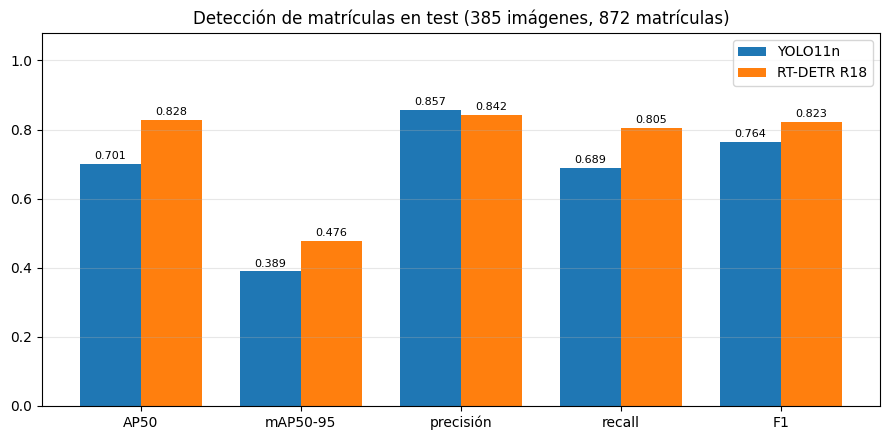

In [21]:
metricas = ["AP50", "mAP50-95", "precisión", "recall", "F1"]
fig, ax = plt.subplots(figsize=(9, 4.5))
ancho = 0.38
for k, (nombre, r) in enumerate(resultados_test.items()):
    pos = np.arange(len(metricas)) + (k - 0.5) * ancho   # una barra a cada lado de cada métrica
    barras = ax.bar(pos, [r[m] for m in metricas], ancho, label=nombre)
    ax.bar_label(barras, fmt="%.3f", fontsize=8, padding=2)
ax.set_xticks(np.arange(len(metricas)), metricas)
ax.set_ylim(0, 1.08)
ax.set_title("Detección de matrículas en test (385 imágenes, 872 matrículas)")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(GRAFICAS / "comparativa_test.png", dpi=120)
plt.show()

### Análisis de los resultados en test

| Modelo | AP50 | mAP50-95 | Precisión | Recall | F1 | TP | FP | FN | ms/imagen |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| YOLO11n (conf 0.25) | 0.701 | 0.389 | **0.857** | 0.689 | 0.764 | 601 | **100** | 271 | **9.2** |
| RT-DETR R18 (conf 0.40) | **0.828** | **0.476** | 0.842 | **0.805** | **0.823** | **702** | 132 | **170** | 41.4 |

- **RT-DETR detecta mejor**: +0,13 en AP50 y +0,09 en mAP50-95. La diferencia está sobre todo en el **recall**: encuentra 101 matrículas más (702 frente a 601 de 872); YOLO se deja casi un tercio sin detectar.
- **La precisión es parecida** (0,84-0,86): cuando cualquiera de los dos dice "matrícula", casi siempre acierta.
- **YOLO11n es unas 4,5 veces más rápido** (9,2 frente a 41,4 ms por imagen en la RTX 3050) y mucho más ligero (2,6 M de parámetros frente a 20,1 M). Los tiempos varían de una ejecución a otra según el estado del portátil (en distintas ejecuciones han salido entre 9 y 17 ms para YOLO y entre 41 y 59 ms para RT-DETR), pero YOLO es siempre entre 3,5 y 5 veces más rápido.
- Los valores coinciden con los de validación (sección 4.3), así que ninguno de los dos está sobreajustado al conjunto de validación.

*Comprobación*: evaluando YOLO con el protocolo exacto de su cuaderno (dataset original, sus JSON y la imagen leída desde disco) se obtiene AP50 0,685 y mAP50-95 0,378, algo menos que aquí. Por tanto, usar las anotaciones corregidas de `dataset_1920` no perjudica a YOLO.

En resumen: para esta práctica, en la que importa encontrar el mayor número posible de matrículas y el vídeo se procesa sin prisa, **RT-DETR es la mejor opción**. **YOLO11n sería preferible para tiempo real** o equipos modestos, donde su velocidad y su tamaño compensan las matrículas que se pierden.

---